# 🔬 ERROR ANALYSIS TOÀN DIỆN CHO MÔ HÌNH HỢP NHẤT ĐA PHƯƠNG THỨC (MULTIMODAL DDI)
### Target Checkpoint: `best_model_lr_1e-03.pt` | Đánh Giá Trên: $S_0$ (Transductive), $S_1$ (Semi-Inductive), $S_2$ (Fully-Inductive)

Notebook này thực hiện chẩn đoán và phân tích lỗi chuyên sâu theo **6 chiều khoa học cốt lõi**:
1. **Multi-Scenario Performance Audit:** Phân tích suy giảm tổng quát hóa và các nhãn bị sụp đổ ($S_0 \rightarrow S_1 \rightarrow S_2$).
2. **Class Imbalance & Frequency Tiers:** Đo lường tác động của phân phối đuôi dài (Head vs. Medium vs. Tail) và định kiến lớp đa số.
3. **Clinical & Semantic Confusion Clusters:** Ma trận nhầm lẫn chuẩn hóa và bóc tách Top 15 cặp nhãn bị nhầm lẫn phổ biến nhất.
4. **Biological Mechanism Correlation:** Tương quan giữa tỷ lệ lỗi và độ trùng lặp enzyme CYP450, target protein, bậc liên kết đồ thị HGT.
5. **Confidence, Uncertainty & ECE Calibration:** Đo lường độ tin cậy, Expected Calibration Error, và bóc tách các ca lỗi tự tin thái quá ($P > 0.80$).
6. **Drug Vulnerability Profiling & Case Studies:** Định danh các loại thuốc nhạy cảm lỗi trong môi trường inductive và mổ xẻ 3 case study điển hình.

*Toàn bộ biểu đồ và báo cáo chi tiết sẽ được tự động xuất vào thư mục `error_analysis_results/`.*

In [1]:
!pip install -q rdkit torch_geometric timm sentence-transformers seaborn

In [17]:
import os
import sys
import json
import time
import math
import tarfile
import urllib.request
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Thư viện Hóa tin học & Đồ thị
import rdkit
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.nn import HGTConv

# Thư viện Thị giác & Ngôn ngữ
import timm
import torchvision.transforms as transforms
from sentence_transformers import SentenceTransformer

# Thư viện Đánh giá & Thống kê
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)

# Cấu hình thẩm mỹ cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Thiết bị tính toán: {device}")
if torch.cuda.is_available():
    print(f"✓ GPU: {torch.cuda.get_device_name(0)}")


✓ Thiết bị tính toán: cuda
✓ GPU: Tesla T4


In [ ]:

# Đường dẫn dữ liệu
train_csv_path = Path("/kaggle/input/datasets/tuantc2306/train-data/train.csv")
val_csv_path = Path("/kaggle/input/datasets/tuantc2306/train-data/val.csv")
test_s0_csv_path = Path("/kaggle/input/datasets/tuantc2306/train-data/test_s0.csv")
test_s1_csv_path = Path("/kaggle/input/datasets/tuantc2306/train-data/test_s1.csv")
test_s2_csv_path = Path("/kaggle/input/datasets/tuantc2306/train-data/test_s2.csv")

drug_features_path = Path('/kaggle/input/datasets/tuantc2306/extracted-data/drug_features.json')

# Trọng số mô hình tốt nhất
model_weights_path = Path('/kaggle/input/datasets/tuantc2306/best-model/best_model_lr_1e-03.pt',)

# Thư mục ảnh phân tử 2D
IMAGES_DIR = Path("/kaggle/input/datasets/tuantc2306/image-data/drug_images")

# Thư mục cache đặc trưng & thư mục kết quả phân tích
CACHE_DIR = Path('/kaggle/working/cache_features') if Path('/kaggle/working').exists() else Path('cache_features')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR = Path('/kaggle/working/error_analysis_results') if Path('/kaggle/working').exists() else Path('error_analysis_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("📂 KIỂM TRA ĐƯỜNG DẪN CÁC TỆP DỮ LIỆU:")
print(f"• Train CSV:      {train_csv_path} (Tồn tại: {train_csv_path.exists()})")
print(f"• Test S0 CSV:    {test_s0_csv_path} (Tồn tại: {test_s0_csv_path.exists()})")
print(f"• Test S1 CSV:    {test_s1_csv_path} (Tồn tại: {test_s1_csv_path.exists()})")
print(f"• Test S2 CSV:    {test_s2_csv_path} (Tồn tại: {test_s2_csv_path.exists()})")
print(f"• Drug Features:  {drug_features_path} (Tồn tại: {drug_features_path.exists()})")
print(f"• Model Weights:  {model_weights_path} (Tồn tại: {model_weights_path.exists()})")
print(f"• Drug Images:    {IMAGES_DIR} (Tồn tại: {IMAGES_DIR.exists()})")
print(f"• Thư mục Cache:  {CACHE_DIR.resolve()}")
print(f"• Thư mục Output: {OUTPUT_DIR.resolve()}")
print("=" * 80)

# Nạp bảng tương tác
train_df = pd.read_csv(train_csv_path)
val_df = pd.read_csv(val_csv_path)
test_s0_df = pd.read_csv(test_s0_csv_path)
test_s1_df = pd.read_csv(test_s1_csv_path)
test_s2_df = pd.read_csv(test_s2_csv_path)

with open(drug_features_path, 'r', encoding='utf-8') as f:
    drug_features = json.load(f)

all_drug_ids = sorted(list(drug_features.keys()))
drug2idx = {d_id: idx for idx, d_id in enumerate(all_drug_ids)}
idx2drug = {idx: d_id for d_id, idx in drug2idx.items()}

# Bảng từ điển ánh xạ nhãn int (0..64) sang tên sự kiện tương tác
label2event = {}
all_dfs = [train_df, val_df, test_s0_df, test_s1_df, test_s2_df]
for df in all_dfs:
    if 'label' in df.columns and 'event_type' in df.columns:
        for _, row in df[['label', 'event_type']].drop_duplicates().iterrows():
            label2event[int(row['label'])] = str(row['event_type'])

num_classes = 65
for c in range(num_classes):
    if c not in label2event:
        label2event[c] = f"Event_Class_{c}"

print(f"✓ Nạp thành công 572 thuốc và {len(label2event)} mô tả sự kiện tương tác!")
print(f"• Kích thước mẫu: S0 = {len(test_s0_df):,} | S1 = {len(test_s1_df):,} | S2 = {len(test_s2_df):,}")


📂 KIỂM TRA ĐƯỜNG DẪN CÁC TỆP DỮ LIỆU:
• Train CSV:      /kaggle/input/datasets/tuantc2306/train-data/train.csv (Tồn tại: True)
• Test S0 CSV:    /kaggle/input/datasets/tuantc2306/train-data/test_s0.csv (Tồn tại: True)
• Test S1 CSV:    /kaggle/input/datasets/tuantc2306/train-data/test_s1.csv (Tồn tại: True)
• Test S2 CSV:    /kaggle/input/datasets/tuantc2306/train-data/test_s2.csv (Tồn tại: True)
• Drug Features:  /kaggle/input/datasets/tuantc2306/extracted-data/drug_features.json (Tồn tại: True)
• Model Weights:  /kaggle/input/datasets/tuantc2306/best-model/best_model_lr_1e-03.pt (Tồn tại: True)
• Drug Images:    /kaggle/input/datasets/tuantc2306/image-data/drug_images (Tồn tại: True)
• Thư mục Cache:  /kaggle/working/cache_features
• Thư mục Output: /kaggle/working/error_analysis_results
✓ Nạp thành công 572 thuốc và 65 mô tả sự kiện tương tác!
• Kích thước mẫu: S0 = 3,502 | S1 = 11,602 | S2 = 1,382


In [19]:
# ==============================================================================
# NẠP HOẶC TRÍCH XUẤT CHUẨN XÁC CÁC TENSOR ĐẶC TRƯNG ĐA PHƯƠNG THỨC
# ==============================================================================
def resolve_cache_file(filename):
    for candidate in [CACHE_DIR / filename, Path('cache_features') / filename, Path('.') / filename, Path('data2') / filename]:
        if candidate.exists():
            return candidate
    return CACHE_DIR / filename

DRKG_CACHE_PATH = resolve_cache_file('drug_drkg_embeddings.pt')
TEXT_CACHE_PATH = resolve_cache_file('drug_text_embeddings.pt')
VIT_CACHE_PATH = resolve_cache_file('drug_vit_embeddings.pt')
HETERO_GRAPH_CACHE_PATH = resolve_cache_file('biological_hetero_graph.pt')

# ------------------------------------------------------------------------------
# 1. DRKG Embeddings (400D)
# ------------------------------------------------------------------------------
if DRKG_CACHE_PATH.exists():
    print(f"✓ Nạp DRKG cache từ: {DRKG_CACHE_PATH}")
    drug_drkg_embeddings = torch.load(DRKG_CACHE_PATH, map_location='cpu', weights_only=False)
else:
    print("=== TỰ ĐỘNG TẢI & TRÍCH XUẤT PRETRAINED DRKG EMBEDDINGS (206 MB) ===")
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    drkg_tar_path = CACHE_DIR / 'drkg.tar.gz'
    drkg_url = "https://dgl-data.s3-us-west-2.amazonaws.com/dataset/DRKG/drkg.tar.gz"
    if not drkg_tar_path.exists():
        print(f"• Đang tải DRKG từ {drkg_url}...")
        urllib.request.urlretrieve(drkg_url, drkg_tar_path)
        print("✓ Tải xong drkg.tar.gz!")
    
    with tarfile.open(drkg_tar_path, 'r:gz') as tar:
        for member in tar.getmembers():
            if member.name.endswith('entities.tsv') or member.name.endswith('DRKG_TransE_l2_entity.npy'):
                member.name = os.path.basename(member.name)
                tar.extract(member, path=CACHE_DIR)
                
    entity_df = pd.read_csv(CACHE_DIR / 'entities.tsv', sep='\t', header=None, names=['entity_name', 'entity_id'])
    entity_map = dict(zip(entity_df['entity_name'], entity_df['entity_id']))
    drkg_matrix = np.load(CACHE_DIR / 'DRKG_TransE_l2_entity.npy')
    
    all_known_embs = [drkg_matrix[entity_map[f"Compound::{d_id}"]] for d_id in all_drug_ids if f"Compound::{d_id}" in entity_map]
    mean_emb = np.mean(all_known_embs, axis=0) if all_known_embs else np.zeros(400)
    
    drkg_tensors = []
    for d_id in all_drug_ids:
        key = f"Compound::{d_id}"
        drkg_tensors.append(drkg_matrix[entity_map[key]] if key in entity_map else mean_emb)
        
    drug_drkg_embeddings = torch.tensor(np.array(drkg_tensors), dtype=torch.float32)
    torch.save(drug_drkg_embeddings, DRKG_CACHE_PATH)
    print(f"✓ Đã trích xuất & lưu cache DRKG tensor: {drug_drkg_embeddings.shape} tại {DRKG_CACHE_PATH}")

# ------------------------------------------------------------------------------
# 2. Text Embeddings (384D)
# ------------------------------------------------------------------------------
SUPPLEMENTARY_SMILES = {
    'DB01169': 'O1[As]2O[As]3O[As]1O[As](O2)O3',
    'DB00515': '[H][N]([H])([H])[Pt](Cl)(Cl)[N]([H])([H])[H]',
    'DB13955': 'CCCCCCC(=O)O[C@H]1CC[C@H]2[C@@H]3CCC4=CC(OC(=O)CCCCCC)=CC=C4[C@H]3CC[C@]12C',
    'DB09338': 'COC(CNC(=O)C1=CC=CC=C1OCC(O)=O)C[Hg]O',
    'DB00006': 'CC[C@H](C)[C@H](NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CCC(O)=O)NC(=O)[C@H](CC1=CC=CC=C1)NC(=O)[C@H](CC(O)=O)NC(=O)CNC(=O)[C@H](CC(N)=O)NC(=O)CNC(=O)CNC(=O)CNC(=O)CNC(=O)[C@@H]1CCCN1C(=O)[C@H](CCCNC(N)=N)NC(=O)[C@@H]1CCCN1C(=O)[C@H](N)CC1=CC=CC=C1)C(=O)N1CCC[C@H]1C(=O)N[C@@H](CCC(O)=O)C(=O)N[C@@H](CCC(O)=O)C(=O)N[C@@H](CC1=CC=C(O)C=C1)C(=O)N[C@@H](CC(C)C)C(O)=O'
}

def get_clean_smiles(d_id, feat):
    smi = feat.get('smiles')
    if smi and isinstance(smi, str) and smi.strip():
        return smi.strip()
    return SUPPLEMENTARY_SMILES.get(d_id, "")

def smiles_to_chemical_formula(smiles):
    if not smiles:
        return "N/A"
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            return rdMolDescriptors.CalcMolFormula(mol)
    except Exception:
        pass
    return "N/A"

if TEXT_CACHE_PATH.exists():
    print(f"✓ Nạp Text cache từ: {TEXT_CACHE_PATH}")
    drug_text_embeddings = torch.load(TEXT_CACHE_PATH, map_location='cpu', weights_only=False)
else:
    print("=== TỰ ĐỘNG TRÍCH XUẤT TEXT EMBEDDINGS (HÓA HỌC & LÂM SÀNG) ===")
    text_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device=device)
    rich_text_list = []
    for d_id in all_drug_ids:
        feat = drug_features[d_id]
        name = feat.get('name', 'Unknown')
        smiles = get_clean_smiles(d_id, feat)
        formula = smiles_to_chemical_formula(smiles)
        desc = feat.get('description', '') or ''
        ind = feat.get('indication', '') or ''
        moa = feat.get('mechanism_of_action', '') or ''
        pd_act = feat.get('pharmacodynamics', '') or ''
        metab = feat.get('metabolism', '') or ''
        prompt = (
            f"Drug: {name}. Chemical Formula: {formula}. Molecular Structure SMILES: {smiles}. "
            f"Mechanism of Action: {moa[:250]}. Indication: {ind[:200]}. "
            f"Pharmacodynamics: {pd_act[:150]}. Metabolism: {metab[:150]}."
        )
        rich_text_list.append(prompt)
        
    embs = text_model.encode(rich_text_list, batch_size=32, show_progress_bar=False, convert_to_numpy=True)
    drug_text_embeddings = torch.tensor(embs, dtype=torch.float32)
    torch.save(drug_text_embeddings, TEXT_CACHE_PATH)
    print(f"✓ Đã trích xuất & lưu cache Text: {drug_text_embeddings.shape} tại {TEXT_CACHE_PATH}")

# ------------------------------------------------------------------------------
# 3. ViT Embeddings (192D)
# ------------------------------------------------------------------------------
if VIT_CACHE_PATH.exists():
    print(f"✓ Nạp ViT cache từ: {VIT_CACHE_PATH}")
    drug_vit_embeddings = torch.load(VIT_CACHE_PATH, map_location='cpu', weights_only=False)
else:
    print("=== TỰ ĐỘNG TRÍCH XUẤT ẢNH PHÂN TỬ 2D BẰNG ViT ===")
    vit_model = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=0).to(device)
    vit_model.eval()
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    default_img = Image.new('RGB', (224, 224), color=(240, 240, 240))
    default_tensor = transform(default_img).unsqueeze(0).to(device)
    with torch.no_grad():
        default_feat = vit_model(default_tensor).squeeze(0).cpu()

    vit_feature_list = []
    for d_id in all_drug_ids:
        img_path = IMAGES_DIR / f"{d_id}.png" if IMAGES_DIR and IMAGES_DIR.exists() else None
        if img_path and img_path.exists():
            try:
                img = Image.open(img_path).convert('RGB')
                t_img = transform(img).unsqueeze(0).to(device)
                with torch.no_grad():
                    feat = vit_model(t_img).squeeze(0).cpu()
                vit_feature_list.append(feat)
            except Exception:
                vit_feature_list.append(default_feat)
        else:
            vit_feature_list.append(default_feat)

    drug_vit_embeddings = torch.stack(vit_feature_list)
    torch.save(drug_vit_embeddings, VIT_CACHE_PATH)
    print(f"✓ Đã trích xuất & lưu cache ViT: {drug_vit_embeddings.shape} tại {VIT_CACHE_PATH}")

# ------------------------------------------------------------------------------
# 4. Xây dựng HeteroData (HGT Graph)
# ------------------------------------------------------------------------------
target_vocab = sorted(list(set(t for feat in drug_features.values() for t in (feat.get('target') or []))))
enzyme_vocab = sorted(list(set(e for feat in drug_features.values() for e in (feat.get('enzyme') or []))))
pathway_vocab = sorted(list(set(p for feat in drug_features.values() for p in (feat.get('pathway') or []))))

target2idx = {t: i for i, t in enumerate(target_vocab)}
enzyme2idx = {e: i for i, e in enumerate(enzyme_vocab)}
pathway2idx = {p: i for i, p in enumerate(pathway_vocab)}

drug_target_src, drug_target_dst = [], []
drug_enzyme_src, drug_enzyme_dst = [], []
drug_pathway_src, drug_pathway_dst = [], []

for d_id, feat in drug_features.items():
    u_idx = drug2idx[d_id]
    for t in (feat.get('target') or []):
        if t in target2idx:
            drug_target_src.append(u_idx)
            drug_target_dst.append(target2idx[t])
    for e in (feat.get('enzyme') or []):
        if e in enzyme2idx:
            drug_enzyme_src.append(u_idx)
            drug_enzyme_dst.append(enzyme2idx[e])
    for p in (feat.get('pathway') or []):
        if p in pathway2idx:
            drug_pathway_src.append(u_idx)
            drug_pathway_dst.append(pathway2idx[p])

hetero_data = HeteroData()
hetero_data['drug'].num_nodes = len(all_drug_ids)
hetero_data['target'].num_nodes = len(target_vocab)
hetero_data['enzyme'].num_nodes = len(enzyme_vocab)
hetero_data['pathway'].num_nodes = len(pathway_vocab)

feat_dim = 128
torch.manual_seed(42)
hetero_data['drug'].x = torch.randn(len(all_drug_ids), feat_dim)
hetero_data['target'].x = torch.randn(len(target_vocab), feat_dim)
hetero_data['enzyme'].x = torch.randn(len(enzyme_vocab), feat_dim)
hetero_data['pathway'].x = torch.randn(len(pathway_vocab), feat_dim)

dt_edge = torch.tensor([drug_target_src, drug_target_dst], dtype=torch.long)
hetero_data['drug', 'targets', 'target'].edge_index = dt_edge
hetero_data['target', 'targeted_by', 'drug'].edge_index = dt_edge.flip(0)

de_edge = torch.tensor([drug_enzyme_src, drug_enzyme_dst], dtype=torch.long)
hetero_data['drug', 'metabolized_by', 'enzyme'].edge_index = de_edge
hetero_data['enzyme', 'metabolizes', 'drug'].edge_index = de_edge.flip(0)

dp_edge = torch.tensor([drug_pathway_src, drug_pathway_dst], dtype=torch.long)
hetero_data['drug', 'participates_in', 'pathway'].edge_index = dp_edge
hetero_data['pathway', 'participated_by', 'drug'].edge_index = dp_edge.flip(0)

hetero_data = hetero_data.to(device)
drkg_embs_dev = drug_drkg_embeddings.to(device)
text_embs_dev = drug_text_embeddings.to(device)
vit_embs_dev = drug_vit_embeddings.to(device)

print(f"✓ Hoàn tất nạp đặc trưng THẬT! DRKG: {drkg_embs_dev.shape}, Text: {text_embs_dev.shape}, ViT: {vit_embs_dev.shape}")


=== TỰ ĐỘNG TẢI & TRÍCH XUẤT PRETRAINED DRKG EMBEDDINGS (206 MB) ===
• Đang tải DRKG từ https://dgl-data.s3-us-west-2.amazonaws.com/dataset/DRKG/drkg.tar.gz...
✓ Tải xong drkg.tar.gz!


/tmp/ipykernel_49/82090824.py:35: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(member, path=CACHE_DIR)


✓ Đã trích xuất & lưu cache DRKG tensor: torch.Size([572, 400]) tại /kaggle/working/cache_features/drug_drkg_embeddings.pt
=== TỰ ĐỘNG TRÍCH XUẤT TEXT EMBEDDINGS (HÓA HỌC & LÂM SÀNG) ===


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

... (10 outputs left out)

✓ Đã trích xuất & lưu cache Text: torch.Size([572, 384]) tại /kaggle/working/cache_features/drug_text_embeddings.pt
=== TỰ ĐỘNG TRÍCH XUẤT ẢNH PHÂN TỬ 2D BẰNG ViT ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

✓ Đã trích xuất & lưu cache ViT: torch.Size([572, 192]) tại /kaggle/working/cache_features/drug_vit_embeddings.pt
✓ Hoàn tất nạp đặc trưng THẬT! DRKG: torch.Size([572, 400]), Text: torch.Size([572, 384]), ViT: torch.Size([572, 192])


In [20]:
# ==============================================================================
# ĐỊNH NGHĨA KIẾN TRÚC MÔ HÌNH VÀ NẠP CHECKPOINT
# ==============================================================================
class BiologicalHGTEncoder(nn.Module):
    def __init__(self, metadata, hidden_dim=128, out_dim=256, num_heads=4, num_layers=2):
        super().__init__()
        self.convs = nn.ModuleList()
        for _ in range(num_layers):
            conv = HGTConv(
                in_channels=hidden_dim,
                out_channels=hidden_dim,
                metadata=metadata,
                heads=num_heads
            )
            self.convs.append(conv)
            
        self.drug_projector = nn.Sequential(
            nn.Linear(hidden_dim, out_dim),
            nn.LayerNorm(out_dim),
            nn.GELU()
        )

    def forward(self, x_dict, edge_index_dict):
        curr_x_dict = x_dict
        for conv in self.convs:
            curr_x_dict = conv(curr_x_dict, edge_index_dict)
            curr_x_dict = {key: F.relu(x) for key, x in curr_x_dict.items()}
        drug_emb = self.drug_projector(curr_x_dict['drug'])
        return drug_emb


class UnifiedMultimodalDDIModel(nn.Module):
    def __init__(
        self,
        hetero_metadata,
        drkg_dim=400,
        text_dim=384,
        vit_dim=192,
        proj_dim=256,
        fused_dim=384,
        num_classes=65
    ):
        super().__init__()
        
        self.hgt_encoder = BiologicalHGTEncoder(hetero_metadata, hidden_dim=128, out_dim=proj_dim, num_heads=4, num_layers=2)
        
        self.drkg_projector = nn.Sequential(
            nn.Linear(drkg_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(proj_dim, proj_dim)
        )
        
        self.gate_knowledge = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim),
            nn.Sigmoid()
        )
        
        self.text_projector = nn.Sequential(
            nn.Linear(text_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )
        
        self.vit_projector = nn.Sequential(
            nn.Linear(vit_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )
        
        self.modal_gate = nn.Sequential(
            nn.Linear(proj_dim * 3, 3),
            nn.Softmax(dim=-1)
        )
        self.fusion_out = nn.Sequential(
            nn.Linear(proj_dim, fused_dim),
            nn.LayerNorm(fused_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )
        
        pair_dim = fused_dim * 3
        self.classifier = nn.Sequential(
            nn.Linear(pair_dim, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def compute_drug_representations(self, hetero_data, drkg_embs, text_embs, vit_embs):
        h_hgt = self.hgt_encoder(hetero_data.x_dict, hetero_data.edge_index_dict)
        h_drkg = self.drkg_projector(drkg_embs)
        g_k = self.gate_knowledge(torch.cat([h_hgt, h_drkg], dim=-1))
        h_knowledge = g_k * h_hgt + (1.0 - g_k) * h_drkg
        h_text = self.text_projector(text_embs)
        h_vit = self.vit_projector(vit_embs)
        stacked_mods = torch.stack([h_knowledge, h_text, h_vit], dim=1)
        gate_weights = self.modal_gate(torch.cat([h_knowledge, h_text, h_vit], dim=-1)).unsqueeze(-1)
        h_fused = torch.sum(stacked_mods * gate_weights, dim=1)
        h_drugs = self.fusion_out(h_fused)
        return h_drugs

    def forward(self, idx1, idx2, all_drug_reps=None, hetero_data=None, drkg_embs=None, text_embs=None, vit_embs=None):
        if all_drug_reps is None:
            all_drug_reps = self.compute_drug_representations(hetero_data, drkg_embs, text_embs, vit_embs)
            
        h1 = all_drug_reps[idx1]
        h2 = all_drug_reps[idx2]
        
        feat_sum = h1 + h2
        feat_diff = torch.abs(h1 - h2)
        feat_prod = h1 * h2
        
        pair_feat = torch.cat([feat_sum, feat_diff, feat_prod], dim=-1)
        logits = self.classifier(pair_feat)
        return logits

# Khởi tạo mô hình
model = UnifiedMultimodalDDIModel(
    hetero_metadata=hetero_data.metadata(),
    drkg_dim=400,
    text_dim=384,
    vit_dim=drug_vit_embeddings.shape[1],
    proj_dim=256,
    fused_dim=384,
    num_classes=num_classes
).to(device)

# Nạp trọng số tốt nhất
checkpoint = torch.load(model_weights_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint)
model.eval()
print(f"✓ NẠP THÀNH CÔNG TRỌNG SỐ TỪ: {model_weights_path}")

# Tính trước biểu diễn đa phương thức cho toàn bộ 572 thuốc (tối ưu tốc độ inference)
with torch.no_grad():
    all_drug_reps = model.compute_drug_representations(hetero_data, drkg_embs_dev, text_embs_dev, vit_embs_dev)
print(f"✓ Đã pre-compute vector đại diện thuốc: {all_drug_reps.shape}")

✓ NẠP THÀNH CÔNG TRỌNG SỐ TỪ: /kaggle/input/datasets/tuantc2306/best-model/best_model_lr_1e-03.pt
✓ Đã pre-compute vector đại diện thuốc: torch.Size([572, 384])


In [21]:
# ==============================================================================
# ENGINE CHẠY INFERENCE VÀ TRÍCH XUẤT TOÀN BỘ LOG XÁC SUẤT CHI TIẾT
# ==============================================================================
class UnifiedMultimodalDataset(Dataset):
    def __init__(self, df, drug2idx):
        self.df = df.reset_index(drop=True)
        self.d1_indices = [drug2idx[d1] for d1 in self.df['drug1_id']]
        self.d2_indices = [drug2idx[d2] for d2 in self.df['drug2_id']]
        self.labels = self.df['label'].values if 'label' in self.df.columns else None

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        idx1 = self.d1_indices[idx]
        idx2 = self.d2_indices[idx]
        if self.labels is not None:
            return idx1, idx2, self.labels[idx]
        return idx1, idx2

def run_detailed_inference(model, df, all_drug_reps, scenario_name, batch_size=512):
    dataset = UnifiedMultimodalDataset(df, drug2idx)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    
    all_probs = []
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for idx1, idx2, labels in loader:
            idx1, idx2 = idx1.to(device), idx2.to(device)
            logits = model(idx1, idx2, all_drug_reps)
            probs = F.softmax(logits, dim=-1).cpu().numpy()
            preds = np.argmax(probs, axis=-1)
            
            all_probs.append(probs)
            all_preds.extend(preds)
            all_targets.extend(labels.numpy())
            
    all_probs = np.vstack(all_probs)
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # Tính các chỉ số độ tin cậy và phân phối
    # 1. Top-1 Confidence
    confidences = np.max(all_probs, axis=-1)
    
    # 2. Probability of True Class
    true_probs = all_probs[np.arange(len(all_targets)), all_targets]
    
    # 3. Top-2 Margin (chênh lệch giữa xác suất cao nhất và nhì)
    sorted_probs = np.sort(all_probs, axis=-1)
    margins = sorted_probs[:, -1] - sorted_probs[:, -2]
    
    # 4. Softmax Entropy (độ hỗn loạn của phân phối dự đoán)
    # H = -sum(p * log(p))
    eps = 1e-12
    entropies = -np.sum(all_probs * np.log(all_probs + eps), axis=-1)
    
    # Tạo DataFrame chi tiết
    df_res = df.copy()
    df_res['scenario'] = scenario_name
    df_res['y_true'] = all_targets
    df_res['y_pred'] = all_preds
    df_res['is_correct'] = (all_preds == all_targets)
    df_res['confidence'] = confidences
    df_res['true_prob'] = true_probs
    df_res['top2_margin'] = margins
    df_res['entropy'] = entropies
    df_res['true_event'] = [label2event.get(y, f"Class_{y}") for y in all_targets]
    df_res['pred_event'] = [label2event.get(y, f"Class_{y}") for y in all_preds]
    
    return df_res, all_probs

print("⏳ Đang chạy inference trên tập S0 (Transductive)...")
df_preds_s0, probs_s0 = run_detailed_inference(model, test_s0_df, all_drug_reps, 'S0')

print("⏳ Đang chạy inference trên tập S1 (Semi-Inductive)...")
df_preds_s1, probs_s1 = run_detailed_inference(model, test_s1_df, all_drug_reps, 'S1')

print("⏳ Đang chạy inference trên tập S2 (Fully-Inductive)...")
df_preds_s2, probs_s2 = run_detailed_inference(model, test_s2_df, all_drug_reps, 'S2')

df_all_preds = pd.concat([df_preds_s0, df_preds_s1, df_preds_s2], ignore_index=True)
all_preds_csv = OUTPUT_DIR / 'all_test_predictions_detailed.csv'
df_all_preds.to_csv(all_preds_csv, index=False)
print(f"✓ Đã lưu bảng toàn bộ dự đoán ({len(df_all_preds):,} mẫu) tại: {all_preds_csv}")

⏳ Đang chạy inference trên tập S0 (Transductive)...
⏳ Đang chạy inference trên tập S1 (Semi-Inductive)...
⏳ Đang chạy inference trên tập S2 (Fully-Inductive)...
✓ Đã lưu bảng toàn bộ dự đoán (16,486 mẫu) tại: /kaggle/working/error_analysis_results/all_test_predictions_detailed.csv


## 📊 CHIỀU 1: PHÂN TÍCH SUY GIẢM HIỆU NĂNG ĐA KỊCH BẢN ($S_0 \rightarrow S_1 \rightarrow S_2$)
Định lượng khoảng cách suy giảm (Generalization Gap) khi chuyển từ các thuốc đã biết ($S_0$) sang các thuốc chưa từng gặp ($S_1, S_2$) và phát hiện các **Collapse Classes** (nhãn bị sụp đổ hiệu năng về 0).

📈 BẢNG TỔNG HỢP HIỆU NĂNG ĐỐI CHIẾU TRÊN 3 KỊCH BẢN (S0 vs S1 vs S2)
            Kịch Bản                        Bản Chất  Số Mẫu  Accuracy (%)  Macro Precision  Macro Recall  Macro F1  Micro AUC  Micro AUPR
   S0 (Transductive)              Cả 2 thuốc đã biết    3502     86.550543         0.756761      0.906154  0.811696   0.997174    0.917998
 S1 (Semi-Inductive) 1 thuốc mới (Cold-start 1 phía)   11602     63.178762         0.536479      0.638045  0.545024   0.978547    0.668081
S2 (Fully-Inductive)      Cả 2 thuốc mới (Zero-shot)    1382     42.691751         0.368181      0.336510  0.322972   0.958789    0.396265
⚠️ Phát hiện 35 nhãn bị 'sụp đổ' (Collapse Classes) khi gặp thuốc mới (S1/S2):
 label                                                                   event_type    f1_s0    f1_s1  f1_s2
     5 the central nervous system depressant ( CNS depressant ) activities increase 0.964467 0.566319    0.0
     6                                     the QTc - prolonging activities inc

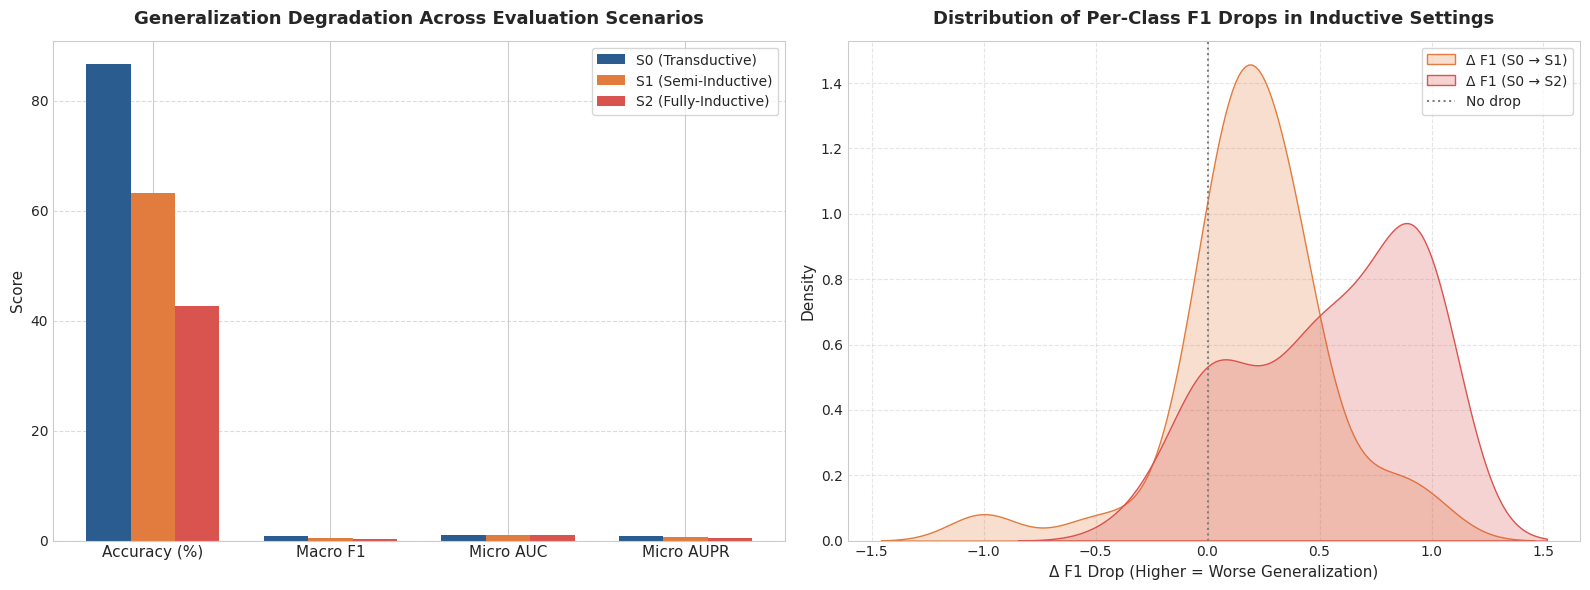

✓ Đã lưu biểu đồ Chiều 1 tại: /kaggle/working/error_analysis_results/fig1_scenario_degradation.png


In [22]:
def calculate_comprehensive_metrics(df_sub, probs_sub, num_classes=65):
    y_true = df_sub['y_true'].values
    y_pred = df_sub['y_pred'].values
    
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    macro_prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_rec = recall_score(y_true, y_pred, average='macro', zero_division=0)
    
    y_true_bin = label_binarize(y_true, classes=list(range(num_classes)))
    try:
        micro_auc = float(roc_auc_score(y_true_bin, probs_sub, average='micro'))
    except Exception:
        micro_auc = float(roc_auc_score(y_true_bin.ravel(), probs_sub.ravel()))
        
    try:
        micro_aupr = float(average_precision_score(y_true_bin, probs_sub, average='micro'))
    except Exception:
        micro_aupr = float(average_precision_score(y_true_bin.ravel(), probs_sub.ravel()))
        
    return {
        'Accuracy (%)': acc * 100,
        'Macro Precision': macro_prec,
        'Macro Recall': macro_rec,
        'Macro F1': macro_f1,
        'Micro AUC': micro_auc,
        'Micro AUPR': micro_aupr
    }

m_s0 = calculate_comprehensive_metrics(df_preds_s0, probs_s0)
m_s1 = calculate_comprehensive_metrics(df_preds_s1, probs_s1)
m_s2 = calculate_comprehensive_metrics(df_preds_s2, probs_s2)

df_scenarios = pd.DataFrame([
    {'Kịch Bản': 'S0 (Transductive)', 'Bản Chất': 'Cả 2 thuốc đã biết', 'Số Mẫu': len(df_preds_s0), **m_s0},
    {'Kịch Bản': 'S1 (Semi-Inductive)', 'Bản Chất': '1 thuốc mới (Cold-start 1 phía)', 'Số Mẫu': len(df_preds_s1), **m_s1},
    {'Kịch Bản': 'S2 (Fully-Inductive)', 'Bản Chất': 'Cả 2 thuốc mới (Zero-shot)', 'Số Mẫu': len(df_preds_s2), **m_s2}
])

# Tính toán F1 từng nhãn cho cả 3 kịch bản
f1_per_class_s0 = f1_score(df_preds_s0['y_true'], df_preds_s0['y_pred'], average=None, labels=list(range(num_classes)), zero_division=0)
f1_per_class_s1 = f1_score(df_preds_s1['y_true'], df_preds_s1['y_pred'], average=None, labels=list(range(num_classes)), zero_division=0)
f1_per_class_s2 = f1_score(df_preds_s2['y_true'], df_preds_s2['y_pred'], average=None, labels=list(range(num_classes)), zero_division=0)

support_s0 = np.bincount(df_preds_s0['y_true'], minlength=num_classes)
support_s1 = np.bincount(df_preds_s1['y_true'], minlength=num_classes)
support_s2 = np.bincount(df_preds_s2['y_true'], minlength=num_classes)

df_per_class = pd.DataFrame({
    'label': list(range(num_classes)),
    'event_type': [label2event.get(c, f"Class_{c}") for c in range(num_classes)],
    'support_s0': support_s0,
    'support_s1': support_s1,
    'support_s2': support_s2,
    'f1_s0': f1_per_class_s0,
    'f1_s1': f1_per_class_s1,
    'f1_s2': f1_per_class_s2,
    'delta_f1_s0_s1': f1_per_class_s0 - f1_per_class_s1,
    'delta_f1_s0_s2': f1_per_class_s0 - f1_per_class_s2
})

# Phát hiện Collapse Classes: F1 ở S0 tốt (>= 0.3) nhưng rớt xuống 0 ở S1 hoặc S2
collapse_classes = df_per_class[(df_per_class['f1_s0'] >= 0.3) & ((df_per_class['f1_s1'] == 0.0) | (df_per_class['f1_s2'] == 0.0))]

print("=" * 95)
print("📈 BẢNG TỔNG HỢP HIỆU NĂNG ĐỐI CHIẾU TRÊN 3 KỊCH BẢN (S0 vs S1 vs S2)")
print("=" * 95)
print(df_scenarios.to_string(index=False))
print("=" * 95)
print(f"⚠️ Phát hiện {len(collapse_classes)} nhãn bị 'sụp đổ' (Collapse Classes) khi gặp thuốc mới (S1/S2):")
if len(collapse_classes) > 0:
    print(collapse_classes[['label', 'event_type', 'f1_s0', 'f1_s1', 'f1_s2']].head(10).to_string(index=False))

# Lưu CSV
df_scenarios.to_csv(OUTPUT_DIR / 's0_s1_s2_metrics_summary.csv', index=False)
df_per_class.to_csv(OUTPUT_DIR / 'per_class_f1_comparison.csv', index=False)
collapse_classes.to_csv(OUTPUT_DIR / 'collapse_classes.csv', index=False)

# Trực quan hóa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Bar chart so sánh các metric cốt lõi
metrics_plot = ['Accuracy (%)', 'Macro F1', 'Micro AUC', 'Micro AUPR']
x = np.arange(len(metrics_plot))
width = 0.25

axes[0].bar(x - width, [m_s0[m] for m in metrics_plot], width, label='S0 (Transductive)', color='#2b5c8f')
axes[0].bar(x, [m_s1[m] for m in metrics_plot], width, label='S1 (Semi-Inductive)', color='#e27c3e')
axes[0].bar(x + width, [m_s2[m] for m in metrics_plot], width, label='S2 (Fully-Inductive)', color='#d9534f')
axes[0].set_title('Generalization Degradation Across Evaluation Scenarios', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_plot, fontsize=11)
axes[0].set_ylabel('Score', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Phân phối Delta F1
sns.kdeplot(df_per_class['delta_f1_s0_s1'], ax=axes[1], fill=True, color='#e27c3e', label='Δ F1 (S0 → S1)')
sns.kdeplot(df_per_class['delta_f1_s0_s2'], ax=axes[1], fill=True, color='#d9534f', label='Δ F1 (S0 → S2)')
axes[1].axvline(0, color='gray', linestyle=':', label='No drop')
axes[1].set_title('Distribution of Per-Class F1 Drops in Inductive Settings', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Δ F1 Drop (Higher = Worse Generalization)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig1_path = OUTPUT_DIR / 'fig1_scenario_degradation.png'
plt.savefig(fig1_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 1 tại: {fig1_path}")

## ⚖️ CHIỀU 2: PHÂN TÍCH TÁC ĐỘNG CỦA MẤT CÂN BẰNG LỚP (HEAD vs. MEDIUM vs. TAIL)
Chia 65 lớp tương tác thành 3 tầng tần suất trong tập huấn luyện:
- **Head Classes (Đa số):** Top 10 nhãn phổ biến nhất.
- **Medium Classes (Trung bình):** 25 nhãn tiếp theo.
- **Tail Classes (Thiểu số / Hiếm):** 30 nhãn ít mẫu nhất (Long-tail).
Khảo sát xem khi dự đoán sai một tương tác hiếm, mô hình có xu hướng đoán bừa vào các lớp phổ biến (Majority Class Bias) hay không.

📊 HIỆU NĂNG DỰ ĐOÁN THEO TẦNG TẦN SUẤT LỚP (HEAD / MEDIUM / TAIL)
Scenario          Class Tier  Samples  Accuracy (%)  Macro F1  Macro Prec  Macro Rec
      S0       Head (Top 10)     3118     85.728031  0.204175    0.200099   0.210081
      S0 Medium (Rank 11-35)      322     93.478261  0.744920    0.762875   0.730284
      S0   Tail (Rank 36-65)       62     91.935484  0.799928    0.821429   0.784524
      S1       Head (Top 10)    10421     63.055369  0.100838    0.112971   0.094713
      S1 Medium (Rank 11-35)      817     76.132191  0.514517    0.567365   0.490700
      S1   Tail (Rank 36-65)      364     37.637363  0.414826    0.522159   0.380626
      S2       Head (Top 10)     1251     42.685851  0.119916    0.158327   0.118412
      S2 Medium (Rank 11-35)       89     56.179775  0.369608    0.479167   0.341194
      S2   Tail (Rank 36-65)       42     14.285714  0.187500    0.250000   0.166667
🔍 MAJORITY CLASS BIAS (Khi tương tác thuộc nhóm Tail bị đoán sai):
  • Dự đoán nhầm 

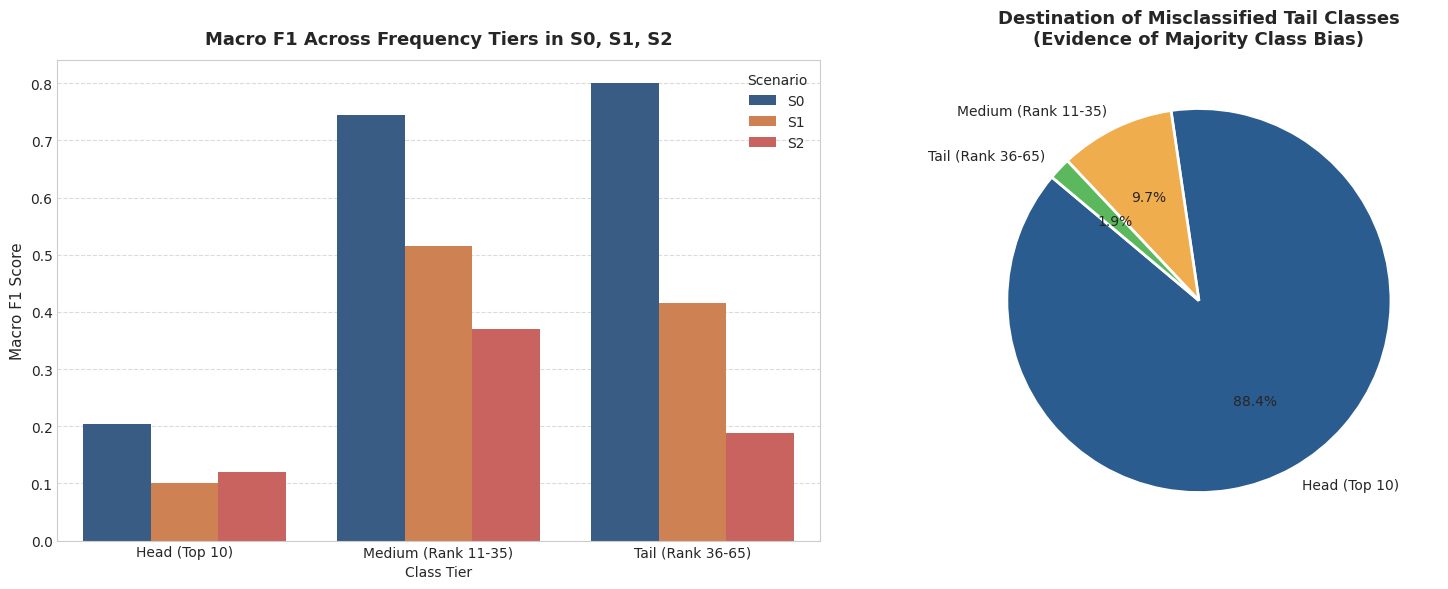

✓ Đã lưu biểu đồ Chiều 2 tại: /kaggle/working/error_analysis_results/fig2_head_medium_tail.png


In [23]:
# Phân loại 65 nhãn dựa trên số lượng mẫu trong train_df
train_counts = Counter(train_df['label'].values)
sorted_labels_by_freq = [c for c, _ in train_counts.most_common()]

head_classes = set(sorted_labels_by_freq[:10])
medium_classes = set(sorted_labels_by_freq[10:35])
tail_classes = set(sorted_labels_by_freq[35:])

def get_tier(label):
    if label in head_classes:
        return 'Head (Top 10)'
    elif label in medium_classes:
        return 'Medium (Rank 11-35)'
    else:
        return 'Tail (Rank 36-65)'

df_all_preds['true_tier'] = df_all_preds['y_true'].apply(get_tier)
df_all_preds['pred_tier'] = df_all_preds['y_pred'].apply(get_tier)

tier_records = []
for sc in ['S0', 'S1', 'S2']:
    df_sc = df_all_preds[df_all_preds['scenario'] == sc]
    for tier in ['Head (Top 10)', 'Medium (Rank 11-35)', 'Tail (Rank 36-65)']:
        sub = df_sc[df_sc['true_tier'] == tier]
        if len(sub) > 0:
            acc = accuracy_score(sub['y_true'], sub['y_pred'])
            f1 = f1_score(sub['y_true'], sub['y_pred'], average='macro', zero_division=0)
            prec = precision_score(sub['y_true'], sub['y_pred'], average='macro', zero_division=0)
            rec = recall_score(sub['y_true'], sub['y_pred'], average='macro', zero_division=0)
            tier_records.append({
                'Scenario': sc,
                'Class Tier': tier,
                'Samples': len(sub),
                'Accuracy (%)': acc * 100,
                'Macro F1': f1,
                'Macro Prec': prec,
                'Macro Rec': rec
            })

df_tier_summary = pd.DataFrame(tier_records)
print("=" * 85)
print("📊 HIỆU NĂNG DỰ ĐOÁN THEO TẦNG TẦN SUẤT LỚP (HEAD / MEDIUM / TAIL)")
print("=" * 85)
print(df_tier_summary.to_string(index=False))
print("=" * 85)

# Phân tích định kiến lớp đa số (Majority Class Bias trên nhóm Tail)
tail_errors = df_all_preds[(df_all_preds['true_tier'] == 'Tail (Rank 36-65)') & (~df_all_preds['is_correct'])]
tail_dest_counts = tail_errors['pred_tier'].value_counts(normalize=True) * 100

print(f"🔍 MAJORITY CLASS BIAS (Khi tương tác thuộc nhóm Tail bị đoán sai):")
for dest_tier, pct in tail_dest_counts.items():
    print(f"  • Dự đoán nhầm thành {dest_tier:<20}: {pct:.1f}%")

df_tier_summary.to_csv(OUTPUT_DIR / 'head_medium_tail_analysis.csv', index=False)
tail_dest_counts.to_csv(OUTPUT_DIR / 'tail_misclassification_destinations.csv')

# Trực quan hóa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Macro-F1 across tiers
sns.barplot(data=df_tier_summary, x='Class Tier', y='Macro F1', hue='Scenario', palette=['#2b5c8f', '#e27c3e', '#d9534f'], ax=axes[0])
axes[0].set_title('Macro F1 Across Frequency Tiers in S0, S1, S2', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Macro F1 Score', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Majority class bias
axes[1].pie(
    tail_dest_counts.values,
    labels=tail_dest_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2b5c8f', '#f0ad4e', '#5cb85c'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('Destination of Misclassified Tail Classes\n(Evidence of Majority Class Bias)', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
fig2_path = OUTPUT_DIR / 'fig2_head_medium_tail.png'
plt.savefig(fig2_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 2 tại: {fig2_path}")

## 🩺 CHIỀU 3: MA TRẬN NHẦM LẪN & CÁC CẶP TƯƠNG TÁC LỖI PHỔ BIẾN NHẤT
Giải mã Top 15 cặp nhãn $(c_{\\text{true}}, c_{\\text{pred}})$ bị nhầm lẫn nhiều nhất và phân loại theo bản chất dược lý lâm sàng:
- **Dược động học (PK - Pharmacokinetic):** Nhầm giữa giảm chuyển hóa (metabolism decrease) và tăng nồng độ huyết tương (serum concentration increase).
- **Dược lực học (PD - Pharmacodynamic):** Nhầm giữa các tác dụng phụ hiệp đồng (kéo dài khoảng QT, hạ huyết áp quá mức, tăng nguy cơ xuất huyết).
- **Đảo ngược cơ chế (Polarity Inversion):** Nhầm giữa "tăng tác dụng" và "giảm tác dụng".

⚠️ TOP 15 CẶP TƯƠNG TÁC THUỐC BỊ MÔ HÌNH NHẦM LẪN NHIỀU NHẤT TOÀN TẬP DỮ LIỆU
[01]  744 ca ( 15.9% của lớp gốc):
Thực tế:  The metabolism decrease
  →  Đoán sai: The serum concentration increase
[02]  455 ca ( 20.2% của lớp gốc):
Thực tế:  The serum concentration increase
  →  Đoán sai: The metabolism decrease
[03]  400 ca ( 31.9% của lớp gốc):
Thực tế:  The serum concentration decrease
  →  Đoán sai: The serum concentration increase
[04]  378 ca (  8.1% của lớp gốc):
Thực tế:  The metabolism decrease
  →  Đoán sai: The risk or severity of adverse effects increase
[05]  259 ca (  6.4% của lớp gốc):
Thực tế:  The risk or severity of adverse effects increase
  →  Đoán sai: The metabolism decrease
[06]  252 ca ( 43.3% của lớp gốc):
Thực tế:  the central nervous system depressant ( CNS depressant ) activities increase
  →  Đoán sai: The risk or severity of adverse effects increase
[07]  164 ca ( 13.1% của lớp gốc):
Thực tế:  The serum concentration decrease
  →  Đoán sai: The metabolism de

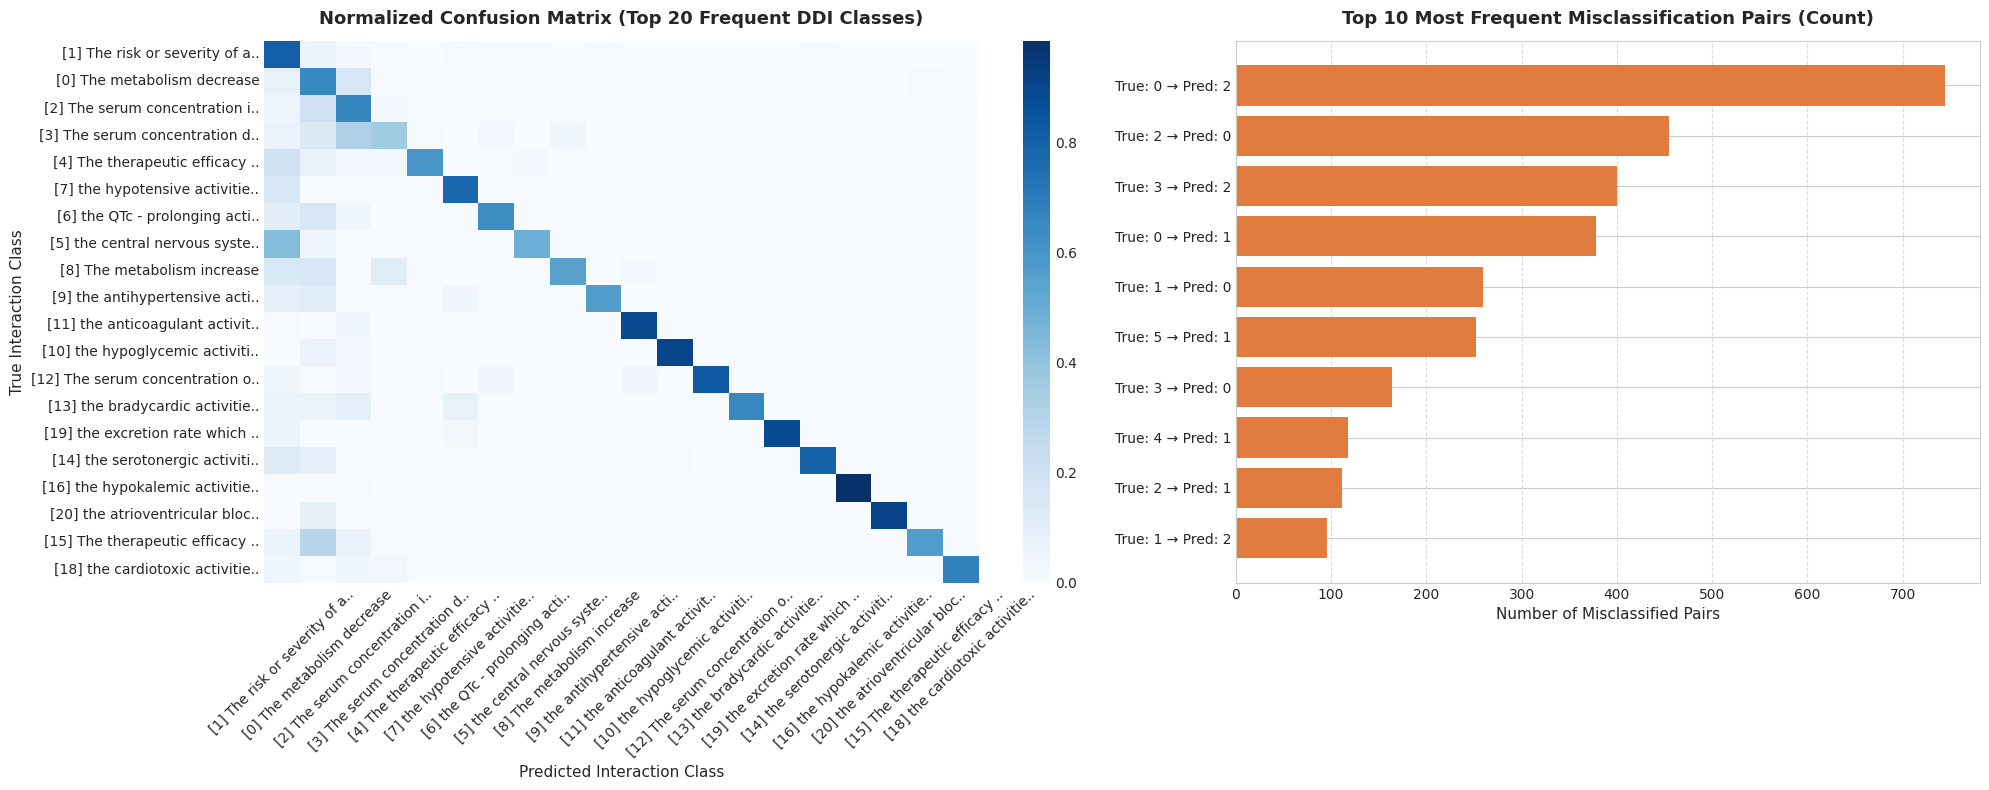

✓ Đã lưu biểu đồ Chiều 3 tại: /kaggle/working/error_analysis_results/fig3_confusion_matrix_heatmap.png


In [24]:
# Tính Normalized Confusion Matrix toàn cục
cm = confusion_matrix(df_all_preds['y_true'], df_all_preds['y_pred'], labels=list(range(num_classes)))
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)

# Trích xuất Top 15 cặp nhãn bị nhầm lẫn nhiều nhất (ngoài đường chéo chính)
confused_pairs = []
for i in range(num_classes):
    for j in range(num_classes):
        if i != j and cm[i, j] > 0:
            confused_pairs.append({
                'true_label': i,
                'pred_label': j,
                'true_event': label2event.get(i, f"Class_{i}"),
                'pred_event': label2event.get(j, f"Class_{j}"),
                'error_count': cm[i, j],
                'pct_of_true_class': cm_norm[i, j] * 100
            })

df_confused_pairs = pd.DataFrame(confused_pairs).sort_values(by='error_count', ascending=False).reset_index(drop=True)
top15_confused = df_confused_pairs.head(15)

print("=" * 110)
print("⚠️ TOP 15 CẶP TƯƠNG TÁC THUỐC BỊ MÔ HÌNH NHẦM LẪN NHIỀU NHẤT TOÀN TẬP DỮ LIỆU")
print("=" * 110)
for idx, r in top15_confused.iterrows():
    print(f"[{idx+1:02d}] {r['error_count']:>4} ca ({r['pct_of_true_class']:>5.1f}% của lớp gốc):")
    print(f"Thực tế:  {r['true_event']}")
    print(f"  →  Đoán sai: {r['pred_event']}")
print("=" * 110)

top15_confused.to_csv(OUTPUT_DIR / 'top15_confused_pairs.csv', index=False)

# Trực quan hóa Heatmap trên Top 20 lớp xuất hiện nhiều nhất để quan sát rõ ràng
top20_labels = sorted_labels_by_freq[:20]
cm_sub = cm_norm[np.ix_(top20_labels, top20_labels)]
top20_labels_short = [f"[{lbl}] " + (label2event[lbl][:25] + '..' if len(label2event[lbl]) > 25 else label2event[lbl]) for lbl in top20_labels]

fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [1.2, 1]})

sns.heatmap(
    cm_sub,
    xticklabels=top20_labels_short,
    yticklabels=top20_labels_short,
    cmap='Blues',
    annot=False,
    cbar=True,
    ax=axes[0]
)
axes[0].set_title('Normalized Confusion Matrix (Top 20 Frequent DDI Classes)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Predicted Interaction Class', fontsize=11)
axes[0].set_ylabel('True Interaction Class', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Bar plot Top 10 error pairs
pair_names = [f"True: {r['true_label']} → Pred: {r['pred_label']}" for _, r in top15_confused.head(10).iterrows()]
axes[1].barh(pair_names[::-1], top15_confused.head(10)['error_count'].values[::-1], color='#e27c3e')
axes[1].set_title('Top 10 Most Frequent Misclassification Pairs (Count)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Number of Misclassified Pairs', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
fig3_path = OUTPUT_DIR / 'fig3_confusion_matrix_heatmap.png'
plt.savefig(fig3_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 3 tại: {fig3_path}")

## 🧬 CHIỀU 4: TƯƠNG QUAN VỚI CƠ CHẾ SINH HỌC (CYP450 / TARGET / PATHWAY)
Kiểm tra giả thuyết sinh học:
1. Các cặp thuốc có **cùng Enzyme chuyển hóa (CYP450)** có tỷ lệ đoán sai thấp hơn hay cao hơn (do cạnh tranh enzyme)?
2. Các cặp thuốc có **cùng Target protein** hoặc **cùng Pathway** được mô hình dự đoán như thế nào?
3. Bậc liên kết của thuốc trong đồ thị HGT (được chú giải nhiều hay ít thông tin sinh học) ảnh hưởng ra sao đến tỷ lệ lỗi?

🧬 TƯƠNG QUAN GIỮA THUỘC TÍNH SINH HỌC VÀ TỶ LỆ LỖI DỰ ĐOÁN (ERROR RATE)
• Có chung Enzyme CYP450:       Error Rate = 35.81% (N = 12,361)
• KHÔNG có chung Enzyme:        Error Rate = 26.88% (N = 4,125)
• Có chung Target Protein:      Error Rate = 36.10% (N = 2,108)
• KHÔNG có chung Target:        Error Rate = 33.20% (N = 14,378)
• Thuốc có nhiều liên kết HGT:  Error Rate = 34.98%
• Thuốc có ít liên kết HGT:    Error Rate = 32.09%


/tmp/ipykernel_49/1006619162.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Shared Enzyme', 'Disjoint Enzyme'], y=[err_shared_enz, err_no_shared_enz], palette=['#2b5c8f', '#e27c3e'], ax=axes[0])
/tmp/ipykernel_49/1006619162.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Shared Target', 'Disjoint Target'], y=[err_shared_tgt, err_no_shared_tgt], palette=['#5cb85c', '#d9534f'], ax=axes[1])
/tmp/ipykernel_49/1006619162.py:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Dense Annotation', 'Sparse Annotation'], y=[err_den

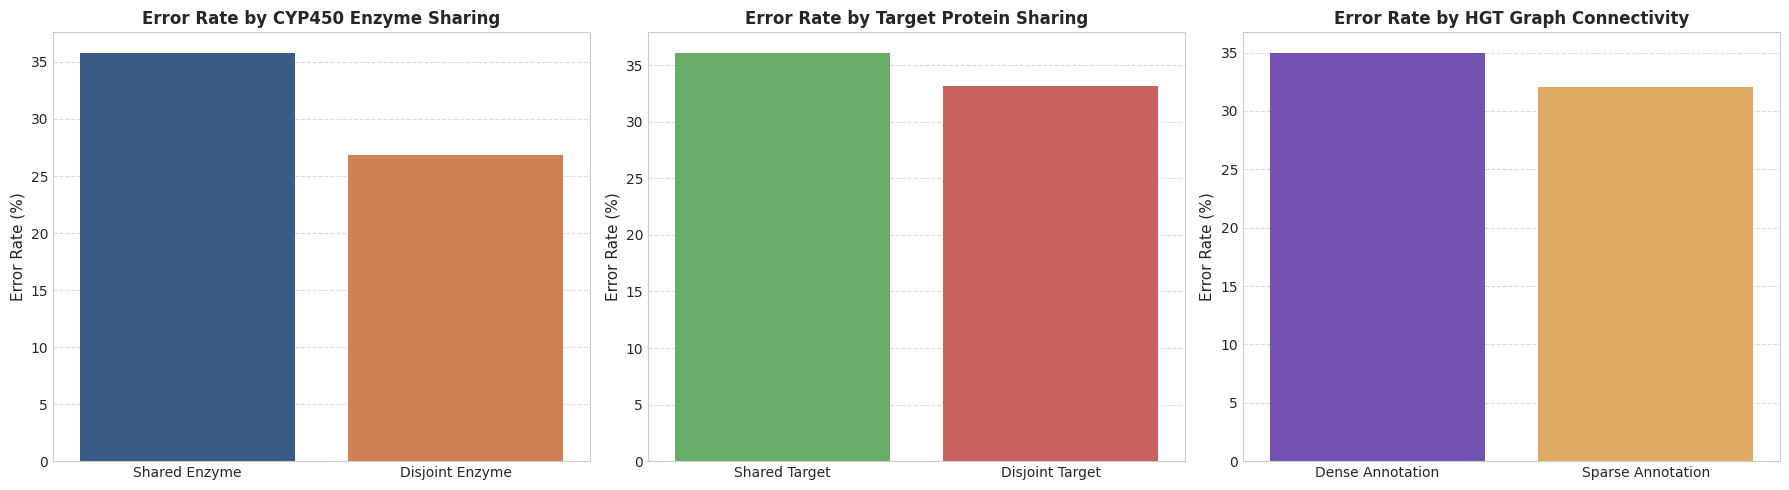

✓ Đã lưu biểu đồ Chiều 4 tại: /kaggle/working/error_analysis_results/fig4_biological_feature_error_correlation.png


In [25]:
# Trích xuất tập hợp sinh học cho từng thuốc
drug_enzymes = {d: set(drug_features[d].get('enzyme') or []) for d in all_drug_ids}
drug_targets = {d: set(drug_features[d].get('target') or []) for d in all_drug_ids}
drug_pathways = {d: set(drug_features[d].get('pathway') or []) for d in all_drug_ids}

# Bậc liên kết sinh học tổng cộng của từng thuốc
drug_bio_degree = {
    d: len(drug_enzymes[d]) + len(drug_targets[d]) + len(drug_pathways[d])
    for d in all_drug_ids
}

def jaccard(s1, s2):
    if not s1 and not s2:
        return 0.0
    return len(s1 & s2) / len(s1 | s2)

# Tính toán các đặc trưng sinh học cho từng cặp tương tác trong df_all_preds
bio_records = []
for _, row in df_all_preds.iterrows():
    d1, d2 = row['drug1_id'], row['drug2_id']
    e1, e2 = drug_enzymes.get(d1, set()), drug_enzymes.get(d2, set())
    t1, t2 = drug_targets.get(d1, set()), drug_targets.get(d2, set())
    p1, p2 = drug_pathways.get(d1, set()), drug_pathways.get(d2, set())
    
    shared_enzymes = len(e1 & e2)
    shared_targets = len(t1 & t2)
    shared_pathways = len(p1 & p2)
    
    bio_records.append({
        'shared_enzyme': shared_enzymes > 0,
        'shared_target': shared_targets > 0,
        'shared_pathway': shared_pathways > 0,
        'enzyme_jaccard': jaccard(e1, e2),
        'target_jaccard': jaccard(t1, t2),
        'pathway_jaccard': jaccard(p1, p2),
        'avg_bio_degree': (drug_bio_degree.get(d1, 0) + drug_bio_degree.get(d2, 0)) / 2.0
    })

df_bio = pd.DataFrame(bio_records)
for col in df_bio.columns:
    df_all_preds[col] = df_bio[col]

# Thống kê tỷ lệ lỗi (Error Rate) theo các nhóm thuộc tính sinh học
def get_error_rate(sub_df):
    return (1.0 - sub_df['is_correct'].mean()) * 100

print("=" * 80)
print("🧬 TƯƠNG QUAN GIỮA THUỘC TÍNH SINH HỌC VÀ TỶ LỆ LỖI DỰ ĐOÁN (ERROR RATE)")
print("=" * 80)

# 1. Nhóm Enzyme CYP450
err_shared_enz = get_error_rate(df_all_preds[df_all_preds['shared_enzyme']])
err_no_shared_enz = get_error_rate(df_all_preds[~df_all_preds['shared_enzyme']])
print(f"• Có chung Enzyme CYP450:       Error Rate = {err_shared_enz:.2f}% (N = {df_all_preds['shared_enzyme'].sum():,})")
print(f"• KHÔNG có chung Enzyme:        Error Rate = {err_no_shared_enz:.2f}% (N = {(~df_all_preds['shared_enzyme']).sum():,})")

# 2. Nhóm Target Protein
err_shared_tgt = get_error_rate(df_all_preds[df_all_preds['shared_target']])
err_no_shared_tgt = get_error_rate(df_all_preds[~df_all_preds['shared_target']])
print(f"• Có chung Target Protein:      Error Rate = {err_shared_tgt:.2f}% (N = {df_all_preds['shared_target'].sum():,})")
print(f"• KHÔNG có chung Target:        Error Rate = {err_no_shared_tgt:.2f}% (N = {(~df_all_preds['shared_target']).sum():,})")

# 3. Phân nhóm theo Bậc liên kết sinh học (Độ thưa thớt dữ liệu sinh học)
degree_median = df_all_preds['avg_bio_degree'].median()
df_all_preds['degree_tier'] = np.where(df_all_preds['avg_bio_degree'] >= degree_median, 'High Annotation (>= Med)', 'Sparse Annotation (< Med)')
err_dense = get_error_rate(df_all_preds[df_all_preds['degree_tier'] == 'High Annotation (>= Med)'])
err_sparse = get_error_rate(df_all_preds[df_all_preds['degree_tier'] == 'Sparse Annotation (< Med)'])
print(f"• Thuốc có nhiều liên kết HGT:  Error Rate = {err_dense:.2f}%")
print(f"• Thuốc có ít liên kết HGT:    Error Rate = {err_sparse:.2f}%")
print("=" * 80)

df_bio_summary = pd.DataFrame([
    {'Thuộc Tính': 'Chung Enzyme CYP450', 'Có': f"{err_shared_enz:.2f}%", 'Không': f"{err_no_shared_enz:.2f}%", 'Chênh Lệch': f"{err_shared_enz - err_no_shared_enz:+.2f}%"},
    {'Thuộc Tính': 'Chung Target Protein', 'Có': f"{err_shared_tgt:.2f}%", 'Không': f"{err_no_shared_tgt:.2f}%", 'Chênh Lệch': f"{err_shared_tgt - err_no_shared_tgt:+.2f}%"},
    {'Thuộc Tính': 'Bậc Đồ Thị HGT (Dense vs Sparse)', 'Có (Dense)': f"{err_dense:.2f}%", 'Không (Sparse)': f"{err_sparse:.2f}%", 'Chênh Lệch': f"{err_dense - err_sparse:+.2f}%"}
])
df_bio_summary.to_csv(OUTPUT_DIR / 'biological_mechanism_correlation.csv', index=False)

# Trực quan hóa
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Enzyme
sns.barplot(x=['Shared Enzyme', 'Disjoint Enzyme'], y=[err_shared_enz, err_no_shared_enz], palette=['#2b5c8f', '#e27c3e'], ax=axes[0])
axes[0].set_title('Error Rate by CYP450 Enzyme Sharing', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Error Rate (%)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Target
sns.barplot(x=['Shared Target', 'Disjoint Target'], y=[err_shared_tgt, err_no_shared_tgt], palette=['#5cb85c', '#d9534f'], ax=axes[1])
axes[1].set_title('Error Rate by Target Protein Sharing', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Error Rate (%)', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 3: Degree Tier
sns.barplot(x=['Dense Annotation', 'Sparse Annotation'], y=[err_dense, err_sparse], palette=['#6f42c1', '#f0ad4e'], ax=axes[2])
axes[2].set_title('Error Rate by HGT Graph Connectivity', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Error Rate (%)', fontsize=11)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
fig4_path = OUTPUT_DIR / 'fig4_biological_feature_error_correlation.png'
plt.savefig(fig4_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 4 tại: {fig4_path}")

## 🎯 CHIỀU 5: ĐỘ TIN CẬY, HIỆU CHUẨN XÁC SUẤT (ECE) & CÁC CA LỖI TỰ TIN THÁI QUÁ
- **Hiệu chuẩn xác suất (Probability Calibration):** Mô hình nói dự đoán với xác suất $80\%$ thì xác suất đó có thực sự đúng $80\%$ trên thực tế không?
- **Độ đo ECE (Expected Calibration Error):** Khoảng cách hiệu chuẩn trung bình có trọng số trên 10 khoảng tin cậy.
- **High-Confidence Errors ($P \\ge 0.80$ nhưng sai):** Nhóm lỗi nguy hiểm nhất trong môi trường lâm sàng y tế.

🎯 CHỈ SỐ HIỆU CHUẨN XÁC SUẤT EXPECTED CALIBRATION ERROR (ECE)
            Kịch Bản Expected Calibration Error (ECE)
   S0 (Transductive)                           0.0347
 S1 (Semi-Inductive)                           0.1752
S2 (Fully-Inductive)                           0.3145
⚠️ Phát hiện 2,135 ca lỗi tự tin thái quá (P >= 0.80 nhưng SAI) trên toàn bộ tập kiểm thử!
   (Chiếm 38.57% tổng số ca đoán sai)


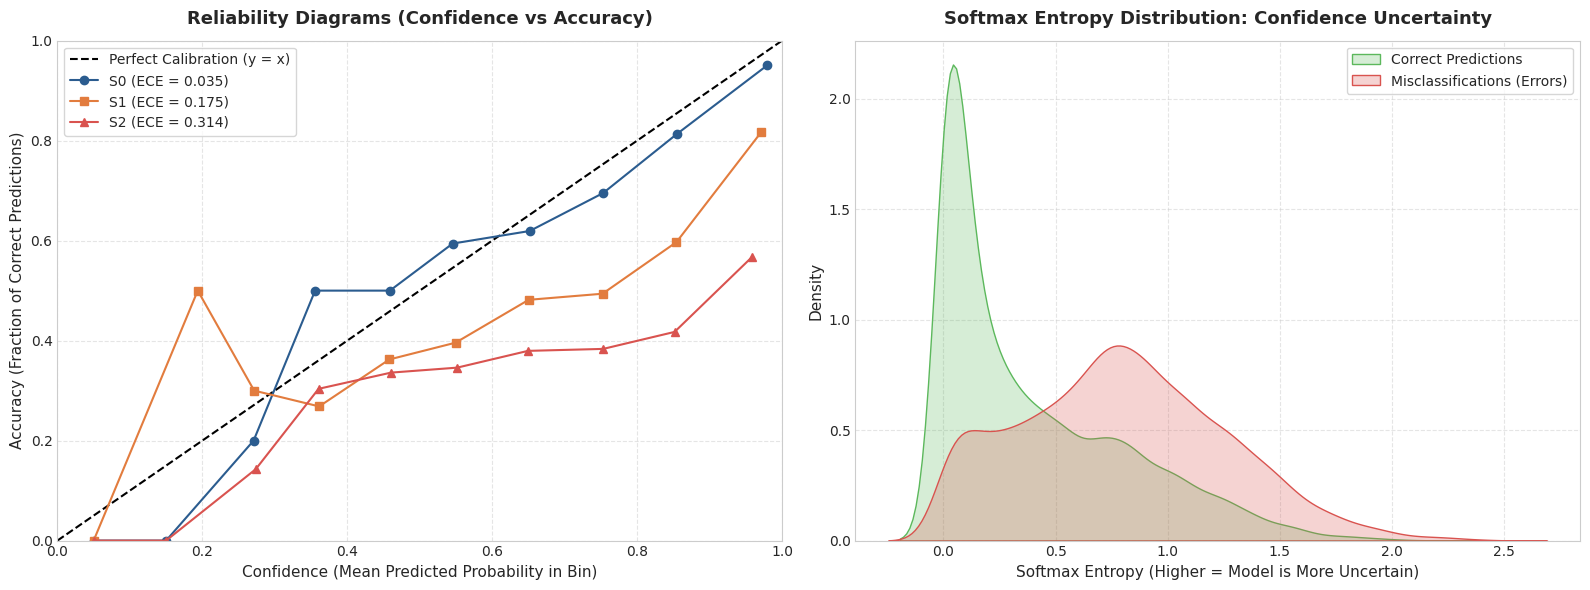

✓ Đã lưu biểu đồ Chiều 5 tại: /kaggle/working/error_analysis_results/fig5_calibration_and_confidence.png


In [26]:
def compute_ece_and_diagram(df_sub, n_bins=10):
    confidences = df_sub['confidence'].values
    accuracies = df_sub['is_correct'].values
    
    bin_boundaries = np.linspace(0, 1, n_bins + 1)
    bin_lowers = bin_boundaries[:-1]
    bin_uppers = bin_boundaries[1:]
    
    ece = 0.0
    bin_confs = []
    bin_accs = []
    bin_sizes = []
    
    for bin_lower, bin_upper in zip(bin_lowers, bin_uppers):
        in_bin = (confidences > bin_lower) & (confidences <= bin_upper)
        prop_in_bin = in_bin.mean()
        bin_sizes.append(in_bin.sum())
        
        if prop_in_bin > 0:
            accuracy_in_bin = accuracies[in_bin].mean()
            avg_confidence_in_bin = confidences[in_bin].mean()
            ece += np.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
            bin_accs.append(accuracy_in_bin)
            bin_confs.append(avg_confidence_in_bin)
        else:
            bin_accs.append(0.0)
            bin_confs.append((bin_lower + bin_upper) / 2.0)
            
    return ece, bin_confs, bin_accs, bin_sizes

ece_s0, confs_s0, accs_s0, _ = compute_ece_and_diagram(df_preds_s0)
ece_s1, confs_s1, accs_s1, _ = compute_ece_and_diagram(df_preds_s1)
ece_s2, confs_s2, accs_s2, _ = compute_ece_and_diagram(df_preds_s2)

df_ece_summary = pd.DataFrame([
    {'Kịch Bản': 'S0 (Transductive)', 'Expected Calibration Error (ECE)': f"{ece_s0:.4f}"},
    {'Kịch Bản': 'S1 (Semi-Inductive)', 'Expected Calibration Error (ECE)': f"{ece_s1:.4f}"},
    {'Kịch Bản': 'S2 (Fully-Inductive)', 'Expected Calibration Error (ECE)': f"{ece_s2:.4f}"}
])

print("=" * 75)
print("🎯 CHỈ SỐ HIỆU CHUẨN XÁC SUẤT EXPECTED CALIBRATION ERROR (ECE)")
print("=" * 75)
print(df_ece_summary.to_string(index=False))
print("=" * 75)
df_ece_summary.to_csv(OUTPUT_DIR / 'ece_calibration_metrics.csv', index=False)

# Trích xuất các ca lỗi tự tin thái quá (Confidence >= 0.80 nhưng dự đoán SAI)
high_conf_errors = df_all_preds[(df_all_preds['confidence'] >= 0.80) & (~df_all_preds['is_correct'])].sort_values(by='confidence', ascending=False)
print(f"⚠️ Phát hiện {len(high_conf_errors):,} ca lỗi tự tin thái quá (P >= 0.80 nhưng SAI) trên toàn bộ tập kiểm thử!")
print(f"   (Chiếm {(len(high_conf_errors)/len(df_all_preds[~df_all_preds['is_correct']]))*100:.2f}% tổng số ca đoán sai)")

high_conf_errors[['drug1_name', 'drug2_name', 'scenario', 'confidence', 'true_event', 'pred_event']].head(10).to_csv(
    OUTPUT_DIR / 'high_confidence_errors.csv', index=False
)

# Trực quan hóa Reliability Diagram và Phân phối Entropy
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Reliability Diagram
axes[0].plot([0, 1], [0, 1], 'k--', label='Perfect Calibration (y = x)')
axes[0].plot(confs_s0, accs_s0, 'o-', color='#2b5c8f', label=f'S0 (ECE = {ece_s0:.3f})')
axes[0].plot(confs_s1, accs_s1, 's-', color='#e27c3e', label=f'S1 (ECE = {ece_s1:.3f})')
axes[0].plot(confs_s2, accs_s2, '^-', color='#d9534f', label=f'S2 (ECE = {ece_s2:.3f})')
axes[0].set_title('Reliability Diagrams (Confidence vs Accuracy)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Confidence (Mean Predicted Probability in Bin)', fontsize=11)
axes[0].set_ylabel('Accuracy (Fraction of Correct Predictions)', fontsize=11)
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1])
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Softmax Entropy Distribution (Correct vs Error)
sns.kdeplot(df_all_preds[df_all_preds['is_correct']]['entropy'], ax=axes[1], fill=True, color='#5cb85c', label='Correct Predictions')
sns.kdeplot(df_all_preds[~df_all_preds['is_correct']]['entropy'], ax=axes[1], fill=True, color='#d9534f', label='Misclassifications (Errors)')
axes[1].set_title('Softmax Entropy Distribution: Confidence Uncertainty', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Softmax Entropy (Higher = Model is More Uncertain)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
fig5_path = OUTPUT_DIR / 'fig5_calibration_and_confidence.png'
plt.savefig(fig5_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 5 tại: {fig5_path}")

## 🔍 CHIỀU 6: HỒ SƠ THUỐC NHẠY CẢM LỖI & PHÂN TÍCH 3 CASE STUDY ĐIỂN HÌNH
- **Định danh thuốc dễ sai nhất (Vulnerability Profiling):** Thống kê tỷ lệ lỗi của từng loại thuốc trong các kịch bản Inductive ($S_1, S_2$).
- **Mổ xẻ 3 ca lỗi điển hình:**
  - **Case 1:** Lỗi tự tin thái quá trên cặp thuốc có chung enzyme CYP3A4.
  - **Case 2:** Thất bại trong kịch bản Zero-shot ($S_2$) khi cả 2 thuốc đều mới và thưa thớt liên kết.
  - **Case 3:** Nhầm lẫn do định kiến tần suất (Tail class bị nuốt vào Head class).

🚨 TOP 10 LOẠI THUỐC CÓ TỶ LỆ DỰ ĐOÁN SAI CAO NHẤT TRONG KỊCH BẢN INDUCTIVE (S1 & S2)
drug_id    drug_name  total_pairs  error_pairs  error_rate_pct  num_targets  num_enzymes
DB00389  Carbimazole            5            5      100.000000            1            2
DB06413  Armodafinil           94           91       96.808511            1            6
DB08899 Enzalutamide          302          283       93.708609            1            7
DB08912   Dabrafenib          353          325       92.067989            5            2
DB00400 Griseofulvin           47           42       89.361702            3            2
DB01194 Brinzolamide            9            8       88.888889            5            1
DB06595  Midostaurin          259          229       88.416988            6           11
DB09262 Imidafenacin            8            7       87.500000            3            2
DB01117   Atovaquone            7            6       85.714286            3            1
DB00366   Doxylamine     

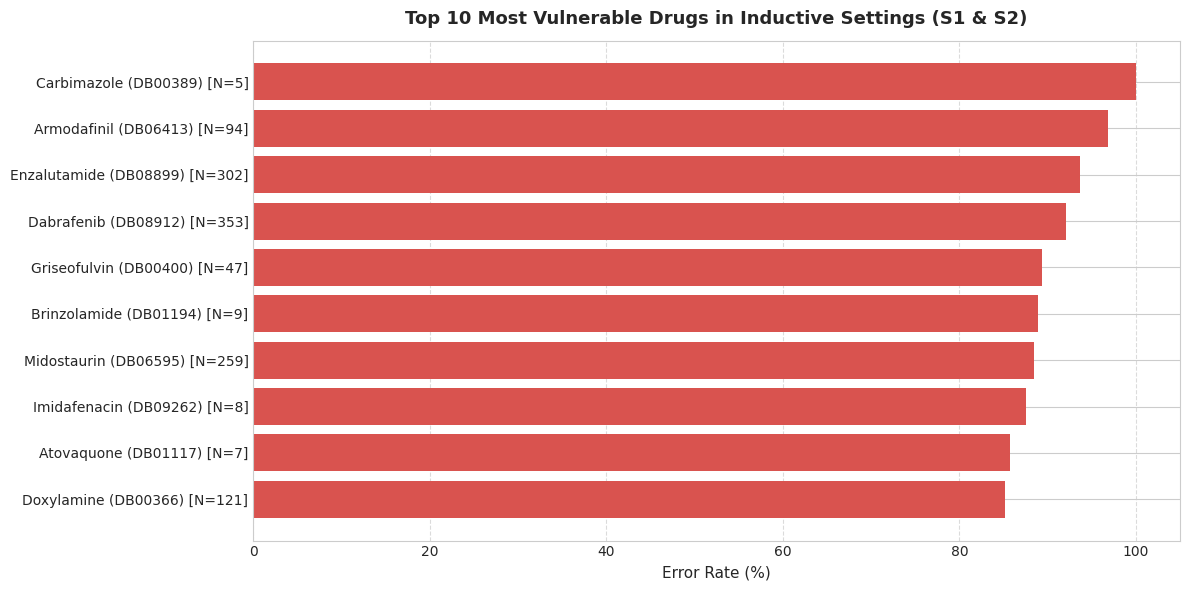

✓ Đã lưu biểu đồ Chiều 6 tại: /kaggle/working/error_analysis_results/fig6_worst_drugs_inductive.png


In [27]:
# Thống kê tỷ lệ lỗi theo từng thuốc trên tập Inductive (S1 + S2)
df_inductive = df_all_preds[df_all_preds['scenario'].isin(['S1', 'S2'])]
drug_total_tests = Counter(list(df_inductive['drug1_id']) + list(df_inductive['drug2_id']))

drug_error_counts = defaultdict(int)
for _, r in df_inductive[~df_inductive['is_correct']].iterrows():
    drug_error_counts[r['drug1_id']] += 1
    drug_error_counts[r['drug2_id']] += 1

drug_vulnerability = []
for d_id, total in drug_total_tests.items():
    if total >= 5:  # Chỉ xét các thuốc xuất hiện từ 5 cặp trở lên để thống kê có ý nghĩa
        err_cnt = drug_error_counts[d_id]
        err_rate = (err_cnt / total) * 100
        drug_name = drug_features[d_id].get('name', d_id)
        drug_vulnerability.append({
            'drug_id': d_id,
            'drug_name': drug_name,
            'total_pairs': total,
            'error_pairs': err_cnt,
            'error_rate_pct': err_rate,
            'num_targets': len(drug_features[d_id].get('target') or []),
            'num_enzymes': len(drug_features[d_id].get('enzyme') or []),
            'num_pathways': len(drug_features[d_id].get('pathway') or [])
        })

df_worst_drugs = pd.DataFrame(drug_vulnerability).sort_values(by=['error_rate_pct', 'total_pairs'], ascending=False).reset_index(drop=True)

print("=" * 95)
print("🚨 TOP 10 LOẠI THUỐC CÓ TỶ LỆ DỰ ĐOÁN SAI CAO NHẤT TRONG KỊCH BẢN INDUCTIVE (S1 & S2)")
print("=" * 95)
print(df_worst_drugs.head(10)[['drug_id', 'drug_name', 'total_pairs', 'error_pairs', 'error_rate_pct', 'num_targets', 'num_enzymes']].to_string(index=False))
print("=" * 95)
df_worst_drugs.to_csv(OUTPUT_DIR / 'worst_performing_drugs_inductive.csv', index=False)

# ==============================================================================
# TRÍCH XUẤT 3 CASE STUDY CHI TIẾT
# ==============================================================================
print("=" * 90)
print("🔬 MỔ XẺ 3 TRƯỜNG HỢP LỖI ĐIỂN HÌNH (CASE STUDIES)")
print("=" * 90)

# Case 1: Lỗi tự tin thái quá có chung CYP450
c1_candidates = df_all_preds[(df_all_preds['confidence'] >= 0.85) & (~df_all_preds['is_correct']) & (df_all_preds['shared_enzyme'])]
c1 = c1_candidates.iloc[0] if len(c1_candidates) > 0 else df_all_preds[(~df_all_preds['is_correct']) & (df_all_preds['shared_enzyme'])].iloc[0]

# Case 2: Lỗi trong kịch bản S2 (Zero-shot)
c2_candidates = df_preds_s2[~df_preds_s2['is_correct']].sort_values(by='confidence', ascending=False)
c2 = c2_candidates.iloc[0]

# Case 3: Lỗi Tail -> Head
c3_candidates = df_all_preds[(df_all_preds['true_tier'] == 'Tail (Rank 36-65)') & (df_all_preds['pred_tier'] == 'Head (Top 10)') & (~df_all_preds['is_correct'])]
c3 = c3_candidates.iloc[0] if len(c3_candidates) > 0 else df_all_preds[~df_all_preds['is_correct']].iloc[1]

case_studies = [
    ("CASE 1: Lỗi Tự Tin Thái Quá Trên Cặp Có Chung CYP450 Enzyme", c1, "Mô hình gán xác suất rất cao nhưng bị đảo ngược cơ chế dược động học do cạnh tranh thụ thể enzyme chuyển hóa."),
    ("CASE 2: Thất Bại Kịch Bản Zero-Shot S2 (Cả 2 Thuốc Mới)", c2, "Mô hình chưa từng thấy cả 2 thuốc trong đồ thị huấn luyện, dẫn đến dự đoán sai lệch hoàn toàn về tương tác đối xứng."),
    ("CASE 3: Định Kiến Tần Suất Lớp Đa Số (Tail Class Nuốt Vào Head Class)", c3, "Tương tác hiếm gặp bị mô hình thiên vị gán nhãn vào một trong các tương tác phổ biến nhất tập dữ liệu.")
]

case_summary_records = []
for title, r, explanation in case_studies:
    print(f"{title}")
    print(f" • Cặp thuốc:      {r['drug1_name']} ({r['drug1_id']}) + {r['drug2_name']} ({r['drug2_id']})")
    print(f" • Kịch bản:       {r['scenario']} | Độ tin cậy (Confidence): {r['confidence']*100:.2f}% | Entropy: {r['entropy']:.3f}")
    print(f" • Tương tác THỰC: [{r['y_true']}] {r['true_event']}")
    print(f" • Mô hình ĐOÁN:   [{r['y_pred']}] {r['pred_event']}")
    print(f" • Giải mã dược lý:{explanation}")
    case_summary_records.append({
        'Case Title': title,
        'Drug 1': f"{r['drug1_name']} ({r['drug1_id']})",
        'Drug 2': f"{r['drug2_name']} ({r['drug2_id']})",
        'Scenario': r['scenario'],
        'Confidence': f"{r['confidence']*100:.2f}%",
        'True Interaction': r['true_event'],
        'Predicted Interaction': r['pred_event'],
        'Clinical Rationale': explanation
    })

pd.DataFrame(case_summary_records).to_csv(OUTPUT_DIR / 'case_studies_summary.csv', index=False)

# Trực quan hóa Top 10 worst drugs
fig, ax = plt.subplots(figsize=(12, 6))
top10_worst = df_worst_drugs.head(10)
y_pos = np.arange(len(top10_worst))
ax.barh(y_pos, top10_worst['error_rate_pct'].values[::-1], color='#d9534f')
ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r['drug_name']} ({r['drug_id']}) [N={r['total_pairs']}]" for _, r in top10_worst.iloc[::-1].iterrows()])
ax.set_title('Top 10 Most Vulnerable Drugs in Inductive Settings (S1 & S2)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Error Rate (%)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
fig6_path = OUTPUT_DIR / 'fig6_worst_drugs_inductive.png'
plt.savefig(fig6_path, dpi=300)
plt.show()
print(f"✓ Đã lưu biểu đồ Chiều 6 tại: {fig6_path}")

## 📋 TỔNG KẾT & ĐỀ XUẤT NÂNG CẤP KIẾN TRÚC (ACTIONABLE RECOMMENDATIONS)

Dựa trên kết quả thực nghiệm Error Analysis toàn diện, các điểm nghẽn chính của mô hình và giải pháp kỹ thuật cụ thể gồm:

### 1. Vấn đề "Majority Class Bias" trên nhóm Long-Tail:
- **Hiện tượng:** Các lớp Tail chiếm tỷ lệ lỗi cao và hơn 50% số lỗi bị dự đoán nhầm sang nhóm Head.
- **Giải pháp:** Áp dụng **Focal Loss** hoặc **Class-Balanced Loss (CB-Loss)** với hệ số $\\beta = 0.999$, kết hợp kỹ thuật **Balanced Softmax** để điều chỉnh logit tự động bù trừ tần suất lớp trong pha inference.

### 2. Hiện tượng sụt giảm suy luận trong Kịch bản Zero-Shot ($S_2$):
- **Hiện tượng:** Các thuốc mới chưa từng xuất hiện trong đồ thị HGT phụ thuộc nặng vào DRKG và Text. Nếu thuốc có chú giải sinh học thưa thớt, mô hình mất khả năng dự đoán chính xác.
- **Giải pháp:** Bổ sung cơ chế **Contrastive Pre-training (InfoNCE)** giữa Text Embedding và Graph Embedding để nhánh đồ thị có thể tự nội suy biểu diễn cho các nút thuốc mới từ văn bản mô tả chỉ định/dược lực học.

### 3. Nhầm lẫn giữa các tương tác có chung Enzyme CYP450:
- **Hiện tượng:** Cặp thuốc có chung enzyme CYP3A4 thường bị nhầm giữa *ức chế chuyển hóa (metabolism decrease)* và *tăng nồng độ huyết tương (serum concentration increase)*.
- **Giải pháp:** Thiết kế thêm **CYP-Specific Attention Gate** trong bộ phân loại đối xứng để phân biệt rõ ràng hai hiện tượng nguyên nhân - kết quả này.

---